In [2]:
import seaborn as sns               # matplotlib 을 더 쉽고 예쁘게 쓰게 해 주는 그래프 라이브러리 (별명 sns)
import pandas as pd                 # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt     # seaborn 이 내부에서 쓰는 그래프 라이브러리 (plt.show() 에 필요)

## Capital Bike Share

- 공유 자전거 회사의 데이터
- 미국 수도인워싱턴DC에서 2012년 1년 동안 일별로 공유자전거 대여 건수를 모아 놓은 데이터이다.





In [3]:
# 하루 = 한 행. 2012년 366일(윤년)치 데이터라서 366행
# 주요 열
#   month, day     : 월, 일
#   workingday     : 근무일 여부 (y = 평일 근무일, n = 주말·공휴일)
#   holiday        : 공휴일 여부 (y = 공휴일, n = 공휴일 아님)
#   registered     : 회원(정기 이용자)의 대여 건수
#   casual         : 비회원(일회성 이용자)의 대여 건수
#   total          : 전체 대여 건수 (registered + casual)
df = pd.read_csv('data/bike.csv')
df

,month,day,quarter,day_of_week,workingday,holiday,temperature,humidity,windspeed,registered,casual,total
0,1,1,1Q,SUN,n,n,21.4,72,12,1608,686,2294
1,1,2,1Q,MON,n,y,15.0,44,19,1707,244,1951
2,1,3,1Q,TUE,y,n,7.6,39,23,2147,89,2236
3,1,4,1Q,WED,y,n,0.4,35,11,2273,95,2368
4,1,5,1Q,THU,y,n,14.2,49,6,3132,140,3272
...,...,...,...,...,...,...,...,...,...,...,...,...
361,12,27,4Q,THU,y,n,10.0,83,24,1867,247,2114
362,12,28,4Q,FRI,y,n,14.0,45,10,2451,644,3095
363,12,29,4Q,SAT,n,n,14.9,72,9,1182,159,1341
364,12,30,4Q,SUN,n,n,16.5,54,26,1432,364,1796


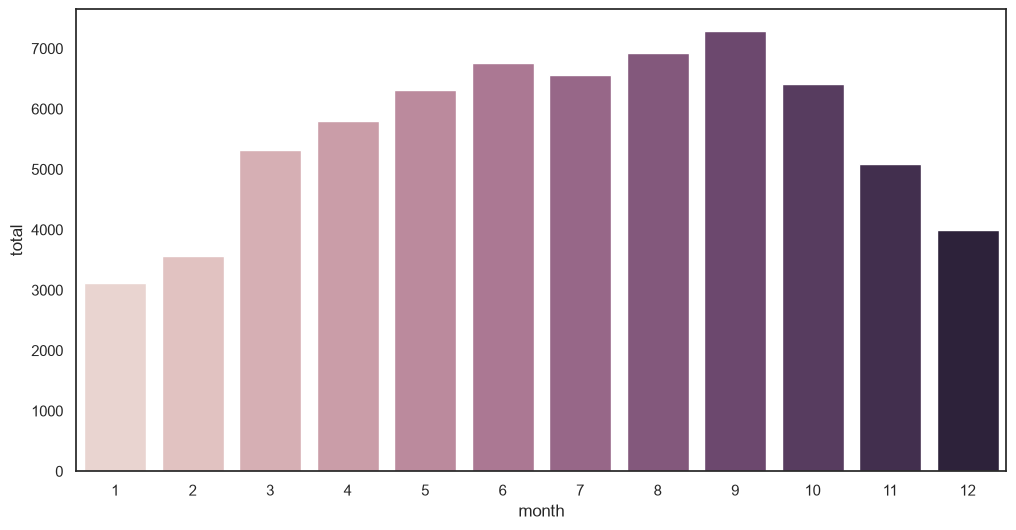

In [12]:
# [월별 하루 평균 대여 건수]
# sns.barplot 은 값을 그대로 그리지 않고, x 값이 같은 행끼리 모아서 '평균'을 막대로 그림
#   예) month 가 1인 행이 31개(1월 1일~31일) → 그 31개의 total 평균이 1월 막대의 높이
# data : 사용할 데이터프레임 / x : x축 열 / y : 평균을 낼 열
# errorbar=None : 막대 위에 생기는 검은 세로선(평균이 얼마나 믿을 만한지 나타내는 오차 막대)을 숨김
# hue='month', legend=False : 막대마다 색을 다르게 칠하기 위한 것 (분석 의미는 없음, 범례는 숨김)
# 결과 : 겨울(1월 약 3,100건)에 가장 적고 9월(약 7,300건)에 가장 많음 → 따뜻할수록 많이 탐
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='total',errorbar=None, hue='month',legend=False)
plt.show()

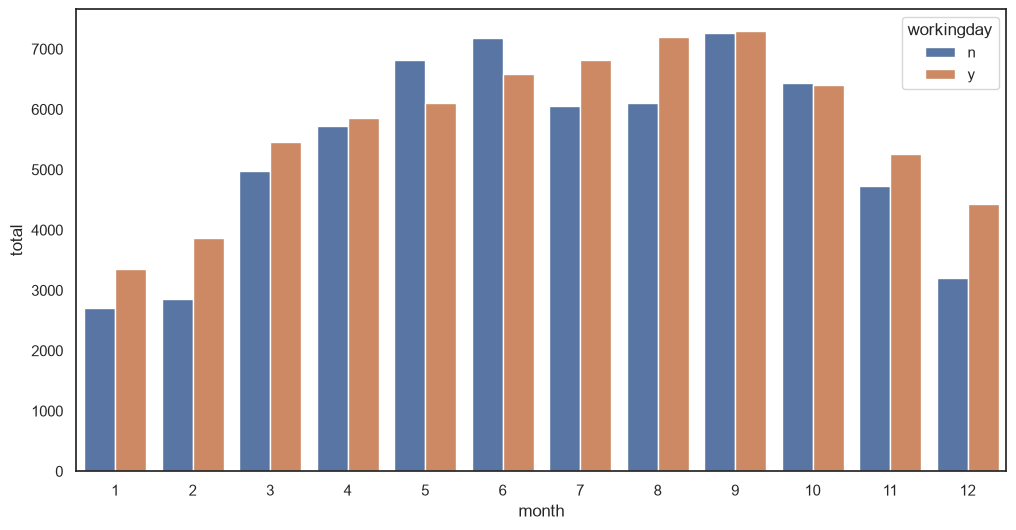

In [14]:
# [hue 로 그룹 나누기 : 월별 평균을 근무일 / 쉬는 날로 쪼개서 비교]
# hue='workingday' : 각 월의 데이터를 workingday 값(y, n)에 따라 두 그룹으로 나눈 뒤
#                    그룹마다 따로 평균을 내서, 색이 다른 막대 2개로 나란히 그림
#   예) 1월 31일 중 근무일(y)인 날들의 total 평균 → 막대 1개
#                   쉬는 날(n)인 날들의 total 평균 → 막대 1개
#   그래서 월마다 막대가 2개씩 생기고, 오른쪽 범례가 어느 색이 y / n 인지 알려 줌
# 읽는 법 : 같은 월 안에서 두 막대의 높이를 비교 → "근무일과 쉬는 날 중 언제 더 많이 빌리나?"
# 결과 : 12달 중 9달은 근무일(y)이 조금 더 높고 5·6·10월은 쉬는 날(n)이 더 높음. 어느 쪽이든 차이가 크지 않음
#        (연평균 근무일 약 5,700건 vs 쉬는 날 약 5,300건)
#        → 전체 합계만 봐서는 뚜렷한 차이가 안 보임. 그래서 아래에서 회원 / 비회원으로 나눠서 다시 봄
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='total',errorbar=None, hue='workingday')
plt.show()

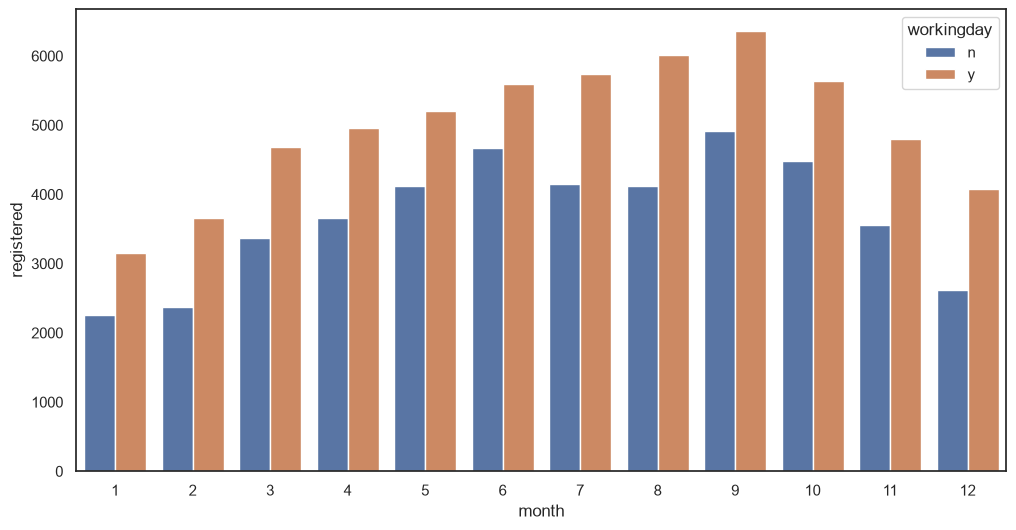

In [15]:
# [회원(registered)만 보기] y 를 total → registered 로 바꿈
# 결과 : 모든 달에서 근무일(y) 막대가 쉬는 날(n) 막대보다 확실히 높음
#        (연평균 근무일 약 5,000건 vs 쉬는 날 약 3,700건)
# 해석 : 회원은 근무일에 더 많이 탄다 → 출퇴근용으로 자전거를 쓰는 사람들이라고 볼 수 있음
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='registered',errorbar=None, hue='workingday')
plt.show()

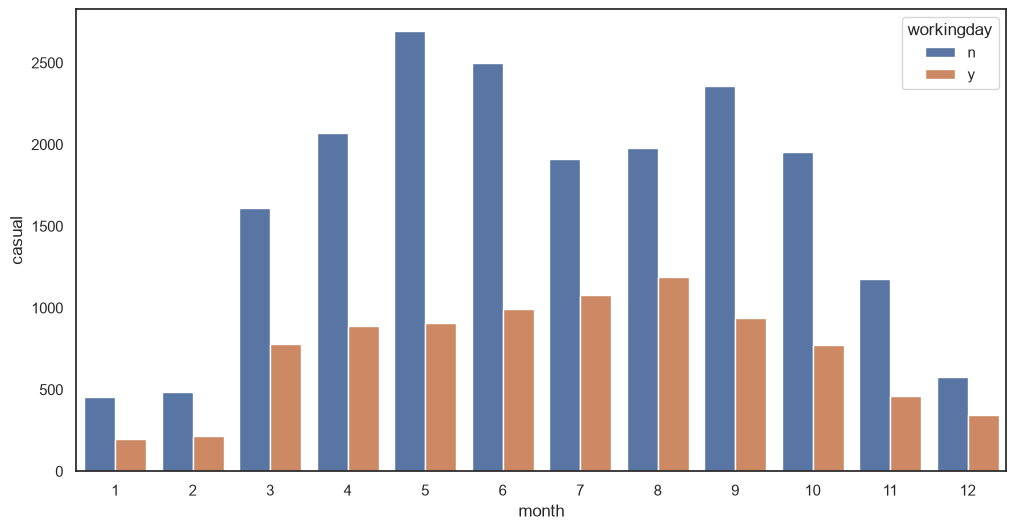

In [ ]:
# [비회원(casual)만 보기] y 를 casual 로 바꿈
# 결과 : 회원과 정반대. 모든 달에서 쉬는 날(n) 막대가 근무일(y) 막대보다 훨씬 높음 (달에 따라 약 1.7~3배)
#        (연평균 쉬는 날 약 1,600건 vs 근무일 약 740건)
# 해석 : 비회원은 쉬는 날에 많이 탄다 → 나들이·관광용으로 가끔 빌리는 사람들이라고 볼 수 있음
# 정리 : total 에서 차이가 안 보였던 이유
#        = 회원(근무일에 많음)과 비회원(쉬는 날에 많음)이 서로 반대라서 합치면 차이가 상쇄됐기 때문
#        → hue 와 y 를 바꿔 가며 쪼개 보면, 합계에 숨어 있던 패턴을 찾을 수 있음
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='casual',errorbar=None, hue='workingday') 
plt.show()

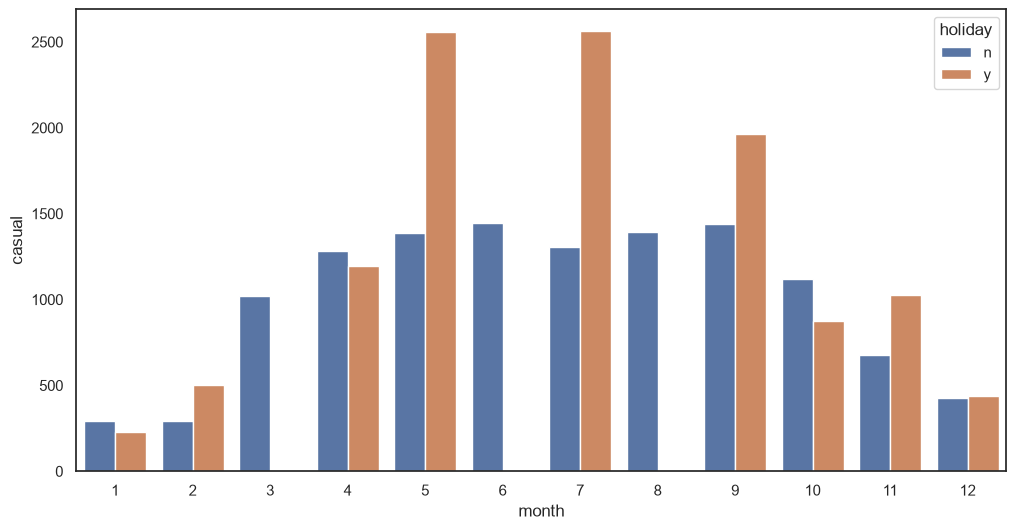

In [19]:
# [hue 를 holiday 로 바꾸기 : 공휴일(y) / 공휴일 아닌 날(n) 로 나눠서 비교]
# workingday 와의 차이 : workingday 의 n 은 주말 + 공휴일, holiday 의 y 는 공휴일만 (주말은 n 에 포함)
# 주의 1 : 3월, 6월, 8월에는 y 막대가 없음 → 그 달에 공휴일이 하루도 없어서 평균을 낼 데이터가 없기 때문
# 주의 2 : 공휴일은 1년에 11일뿐이라, y 막대는 그 달의 공휴일 1~2일만으로 낸 평균임
#          → 그날 날씨 같은 우연에 크게 흔들리므로 월마다 들쭉날쭉함 (5월·7월은 y 가 n 의 약 2배인데, 1월·4월·10월은 오히려 n 이 더 높음)
# 해석 : 이 그래프만으로 "공휴일에 비회원이 더 많이 탄다"고 결론 내리기는 어려움
#        그룹에 속한 데이터 개수가 너무 적으면 평균을 믿기 어렵다는 것을 보여 주는 예
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.barplot(data=df, x= 'month', y='casual',errorbar=None, hue='holiday') 
plt.show()

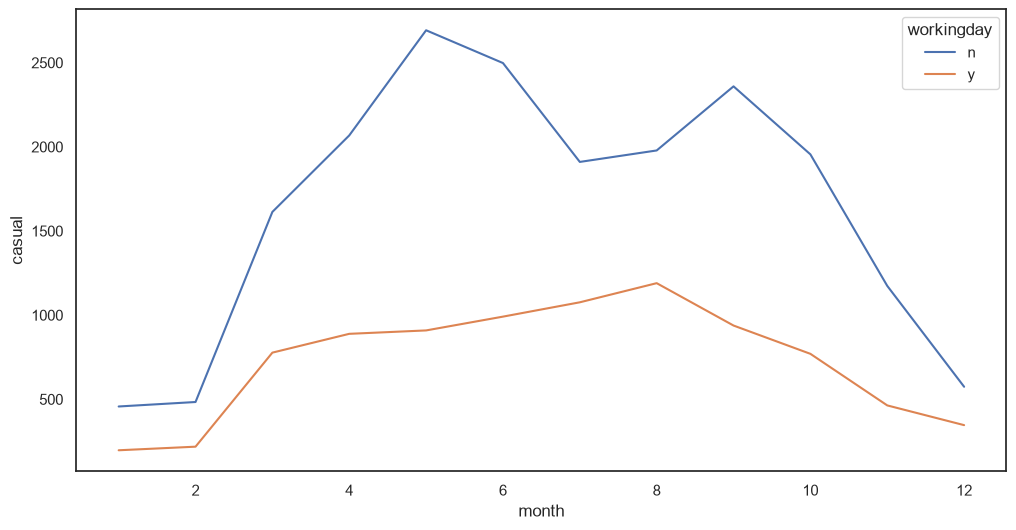

In [20]:
# [같은 내용을 선 그래프로] barplot → lineplot
# lineplot 도 barplot 처럼 x 값이 같은 행끼리 평균을 낸 뒤, 그 평균들을 선으로 이음
# hue='workingday' : 그룹마다 선을 따로 그림 → 근무일(y) 선 1개, 쉬는 날(n) 선 1개
# 막대 그래프보다 좋은 점 : 월이 지나면서 값이 어떻게 변하는지(추세)와 두 그룹의 간격이 한눈에 보임
# 결과 : 쉬는 날(n) 선이 1년 내내 근무일(y) 선보다 위에 있고, 따뜻한 달(4~10월)에 간격이 크게 벌어짐
#        → 비회원은 날씨 좋은 계절의 쉬는 날에 특히 많이 탄다
sns.set_theme(rc={'figure.figsize': (12,6)}, style='white') # 그래프의 가로 12인치 세로 6인치로 변경
sns.lineplot(data=df, x= 'month', y='casual',errorbar=None, hue='workingday') 
plt.show()